# Hotel Booking Analysis — Mac-fixed edition
This notebook retains the original tutorial analysis while correcting its local Windows paths and selected compatibility issues. Keep `hotel_bookings.csv` alongside the notebook.

## 1.. Lets read data !

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
from pathlib import Path
file_path = Path("hotel_bookings.csv")
if not file_path.exists():
    file_path = Path.cwd().parent / "hotel_bookings.csv"
df = pd.read_csv(file_path)


In [6]:
type(df)

pandas.core.frame.DataFrame

In [7]:
df.head(4)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015


In [8]:
df.shape

(119390, 32)

In [9]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [10]:
'''

Categorical data refers to a data type that can be stored 
into groups/categories/labels ..

Examples of categorical variables are :  
age group, educational level,blood type etc.. 


Numerical data refers to the data that is in the form of numbers, 
Examples of numerical data are height, weight, age etc.. 

Numerical data has two categories: discrete data and continuous data


Discrete data : It basically takes countable numbers like 1, 2, 3, 4, 
                5, and so on. 
                In case of infinity, these numbers will keep going on...
                age of a fly : 8 , 9 day etc..
                
Continuous data : which is continuous in nature 
                  amount of sugar , 11.2 kg  , temp of a city  , 
                  your bank balance !
                  
For example, salary levels and performance classifications are 
discrete variables,  whereas height and weight are continuous variables.


'''

'\n\nCategorical data refers to a data type that can be stored \ninto groups/categories/labels ..\n\nExamples of categorical variables are :  \nage group, educational level,blood type etc.. \n\n\nNumerical data refers to the data that is in the form of numbers, \nExamples of numerical data are height, weight, age etc.. \n\nNumerical data has two categories: discrete data and continuous data\n\n\nDiscrete data : It basically takes countable numbers like 1, 2, 3, 4, \n                5, and so on. \n                In case of infinity, these numbers will keep going on...\n                age of a fly : 8 , 9 day etc..\n                \nContinuous data : which is continuous in nature \n                  amount of sugar , 11.2 kg  , temp of a city  , \n                  your bank balance !\n                  \nFor example, salary levels and performance classifications are \ndiscrete variables,  whereas height and weight are continuous variables.\n\n\n'

In [11]:
'''

Categorical data has : Object & bool data-types 
Numerical data have : Integer & Float data-type

'''

'\n\nCategorical data has : Object & bool data-types \nNumerical data have : Integer & Float data-type\n\n'

In [12]:
'''

Variations of int are : ('int64','int32','int16') in numpy library..

Int16 is a 16 bit signed integer , it means it can store both positive & negative values
int16 has has a range of  (2^15 − 1) to -2^15 
int16 has a length of 16 bits (2 bytes).. ie Int16 uses 16 bits 


Int32 is a 32 bit signed integer , it means it stores both positive & negative values
int32 has has a range of (2³¹ − 1) to  -2^31
int32 has a length of 32 bits (4 bytes),, ie Int32 uses 32 bits


Int64 is a 64 bit signed integer , it means it can store both positive & negative values
int64 has has a range of  (2^63 − 1) to -2^63 
int64 has a length of 64 bits (8 bytes) , ie Int64 uses 64 bits.
             

The only difference is that int64 has max range of storing numbers , then comes int32 , then 16 , then int8

That means that Int64’s take up twice as much memory-and doing operations on them may be a lot slower in some machine architectures.

However, Int64’s can represent numbers much more accurately than 32 bit floats.They also allow much larger numbers to be stored..

'''

"\n\nVariations of int are : ('int64','int32','int16') in numpy library..\n\nInt16 is a 16 bit signed integer , it means it can store both positive & negative values\nint16 has has a range of  (2^15 − 1) to -2^15 \nint16 has a length of 16 bits (2 bytes).. ie Int16 uses 16 bits \n\n\nInt32 is a 32 bit signed integer , it means it stores both positive & negative values\nint32 has has a range of (2³¹ − 1) to  -2^31\nint32 has a length of 32 bits (4 bytes),, ie Int32 uses 32 bits\n\n\nInt64 is a 64 bit signed integer , it means it can store both positive & negative values\nint64 has has a range of  (2^63 − 1) to -2^63 \nint64 has a length of 64 bits (8 bytes) , ie Int64 uses 64 bits.\n             \n\nThe only difference is that int64 has max range of storing numbers , then comes int32 , then 16 , then int8\n\nThat means that Int64’s take up twice as much memory-and doing operations on them may be a lot slower in some machine architectures.\n\nHowever, Int64’s can represent numbers much m

## 2.. Lets do Data cleaning !
    Removing invalid rows

In [14]:
df.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015


In [15]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [16]:
filter1 = (df['children']==0) & (df['adults']==0) & (df['babies']==0)

## Adults,babies & children cant be zero at a same time bcz booking couldn't be possible if these 3 attributes are 0 ..

In [17]:
filter1

0         False
1         False
2         False
3         False
4         False
          ...  
119385    False
119386    False
119387    False
119388    False
119389    False
Length: 119390, dtype: bool

In [18]:
df[filter1]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,No Deposit,NaN,174.0,0,Transient-Party,0.00,0,0,Check-Out,10/6/2015
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,No Deposit,NaN,174.0,0,Transient,0.00,0,0,Check-Out,10/12/2015
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,No Deposit,38.0,NaN,0,Transient-Party,0.00,0,0,Check-Out,11/23/2015
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.00,0,0,Check-Out,1/4/2016
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.00,0,0,Check-Out,1/5/2016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,...,No Deposit,7.0,NaN,0,Transient,100.80,0,0,Check-Out,6/30/2017
115091,City Hotel,0,1,2017,June,26,30,0,1,0,...,No Deposit,NaN,NaN,0,Transient,0.00,1,1,Check-Out,7/1/2017
116251,City Hotel,0,44,2017,July,28,15,1,1,0,...,No Deposit,425.0,NaN,0,Transient,73.80,0,0,Check-Out,7/17/2017
116534,City Hotel,0,2,2017,July,28,15,2,5,0,...,No Deposit,9.0,NaN,0,Transient-Party,22.86,0,1,Check-Out,7/22/2017


In [19]:
df.shape

(119390, 32)

In [20]:
df[filter1].shape

(180, 32)

In [21]:
df[~filter1].shape

(119210, 32)

In [22]:
df2 = df[~filter1]

In [23]:
len(df2[(df2['children']==1) & (df2['adults']==0) & (df2['babies']==0)])

4

### Removing Duplicated data

In [25]:
df2.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
119385    False
119386    False
119387    False
119388    False
119389    False
Length: 119210, dtype: bool

In [26]:
type(df2.duplicated())

pandas.core.series.Series

In [27]:
df2.duplicated().sum()

31980

In [28]:
data= df2.drop_duplicates()

In [29]:
data.shape

(87230, 32)

## 3.. Performing descriptive analysis !

In [31]:
data.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [32]:
data[['lead_time' , 'total_of_special_requests' , 'adr']].describe().T

## getting (mean, median , std , percentile) of above features

,count,mean,std,min,25%,50%,75%,max
lead_time,87230.0,79.971019,86.058683,0.00,11.00,49.0,125.0,737.0
total_of_special_requests,87230.0,0.698934,0.832051,0.00,0.00,0.0,1.0,5.0
adr,87230.0,106.518031,54.891227,-6.38,72.25,98.2,134.1,5400.0


In [33]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87230 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87230 non-null  object 
 1   is_canceled                     87230 non-null  int64  
 2   lead_time                       87230 non-null  int64  
 3   arrival_date_year               87230 non-null  int64  
 4   arrival_date_month              87230 non-null  object 
 5   arrival_date_week_number        87230 non-null  int64  
 6   arrival_date_day_of_month       87230 non-null  int64  
 7   stays_in_weekend_nights         87230 non-null  int64  
 8   stays_in_week_nights            87230 non-null  int64  
 9   adults                          87230 non-null  int64  
 10  children                        87226 non-null  float64
 11  babies                          87230 non-null  int64  
 12  meal                            8723

In [34]:
'''

12 features belong to object data-type , ie.. in context to Python ,
they belong to string data-type

16 features belong to int64 nature 

4 features belong to float64 nature  ,


The memory usage of a DataFrame (including the index) is shown when calling the info(). 

 
 
The + symbol indicates that the true memory usage could be higher,  
because pandas does not count the memory used by values in columns 
with dtype=object


Passing memory_usage='deep' will enable a more accurate 
memory usage report ..


'''

"\n\n12 features belong to object data-type , ie.. in context to Python ,\nthey belong to string data-type\n\n16 features belong to int64 nature \n\n4 features belong to float64 nature  ,\n\n\nThe memory usage of a DataFrame (including the index) is shown when calling the info(). \n\n \n \nThe + symbol indicates that the true memory usage could be higher,  \nbecause pandas does not count the memory used by values in columns \nwith dtype=object\n\n\nPassing memory_usage='deep' will enable a more accurate \nmemory usage report ..\n\n\n"

In [35]:
data.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
Index: 87230 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87230 non-null  object 
 1   is_canceled                     87230 non-null  int64  
 2   lead_time                       87230 non-null  int64  
 3   arrival_date_year               87230 non-null  int64  
 4   arrival_date_month              87230 non-null  object 
 5   arrival_date_week_number        87230 non-null  int64  
 6   arrival_date_day_of_month       87230 non-null  int64  
 7   stays_in_weekend_nights         87230 non-null  int64  
 8   stays_in_week_nights            87230 non-null  int64  
 9   adults                          87230 non-null  int64  
 10  children                        87226 non-null  float64
 11  babies                          87230 non-null  int64  
 12  meal                            8723

In [36]:
'''
print quantile values ..

'''

'\nprint quantile values ..\n\n'

In [37]:
for col in ['lead_time', 'total_of_special_requests', 'adr']:
    print('Feature:', col)
    for percentile in range(90, 101):
        quantile_value = data[col].quantile(percentile / 100)
        print(f'{percentile}th percentile: {quantile_value:.2f}')
    print()


Feature: lead_time
90th percentile: 204.00
91th percentile: 212.00
92th percentile: 220.00
93th percentile: 230.00
94th percentile: 241.00
95th percentile: 256.00
96th percentile: 272.00
97th percentile: 291.00
98th percentile: 315.00
99th percentile: 347.00
100th percentile: 737.00

Feature: total_of_special_requests
90th percentile: 2.00
91th percentile: 2.00
92th percentile: 2.00
93th percentile: 2.00
94th percentile: 2.00
95th percentile: 2.00
96th percentile: 2.00
97th percentile: 3.00
98th percentile: 3.00
99th percentile: 3.00
100th percentile: 5.00

Feature: adr
90th percentile: 174.00
91th percentile: 179.00
92th percentile: 185.00
93th percentile: 190.00
94th percentile: 197.10
95th percentile: 204.13
96th percentile: 213.00
97th percentile: 225.00
98th percentile: 239.00
99th percentile: 261.62
100th percentile: 5400.00



In [38]:
np.quantile(data['lead_time'] , q=0.9)

204.0

In [39]:
'''

"adr" feature seems to have Outlier as 99th percentile value 
is 261 but 100th percentile(max value) is 5400 .. 


'''

'\n\n"adr" feature seems to have Outlier as 99th percentile value \nis 261 but 100th percentile(max value) is 5400 .. \n\n\n'

## 4.. Perform Spatial Analysis
        Where do the guests come from ?

In [41]:
not_cancelled = data[data['is_canceled']==0]

In [42]:
not_cancelled.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015


In [43]:
country_wise_data = not_cancelled['country'].value_counts().reset_index()

In [44]:
country_wise_data.columns = ['country' , 'No of guests']

In [45]:
country_wise_data

,country,No of guests
0,PRT,17573
1,GBR,8440
2,FRA,7091
3,ESP,5382
4,DEU,4332
...,...,...
160,ZMB,1
161,SYC,1
162,MDG,1
163,SMR,1


In [46]:
!pip install chart-studio
!pip install plotly

In [47]:
### establishing the entire set-up of Plotly..

## chart_studio import omitted; local offline charts do not require it
## chart_studio provides a web-service for hosting graphs!

import plotly.graph_objs as go
import plotly.express as px

from plotly.offline import download_plotlyjs , init_notebook_mode , plot , iplot

## iplot() when working in a Jupyter Notebook to
## display the plot in the Ipython notebook.

init_notebook_mode(connected=True)

In [48]:
# show on map

map_guest = px.choropleth(data_frame = country_wise_data , 
              locations= country_wise_data['country'] , 
              color=country_wise_data['No of guests'] , 
              hover_name=country_wise_data['country'] , 
              title= "Home country of Guests"
          
             )

In [49]:
map_guest.show()

#### Most guests are from Portugal and other countries in Europe

## 5.. Is any difference between assigned and reserved room types or not ?

In [52]:
data.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [53]:
pivot = pd.crosstab(index = data['reserved_room_type'] , columns=data['assigned_room_type'] , margins=True  )

In [54]:
pivot

assigned_room_type,A,B,C,D,E,F,G,H,I,K,L,All
reserved_room_type,,,,,,,,,,,,
A,45850,892,1253,6402,1034,390,176,94,205,140,0,56436
B,106,872,0,5,2,2,8,0,0,1,0,996
C,5,2,866,6,4,2,10,9,10,0,0,914
D,295,27,32,15979,657,199,82,9,67,29,0,17376
E,15,2,6,22,5458,383,97,4,40,9,0,6036
F,6,14,0,4,31,2636,113,3,10,3,0,2820
G,5,1,2,0,4,14,1999,7,15,3,0,2050
H,0,0,0,1,0,0,10,579,6,0,0,596
L,1,1,1,0,0,1,0,1,0,0,1,6


In [55]:
'''

## lets find meaningful insight from this :

for A category room , 56436 folks have reserved "A" & 45850 folks get assigned_room as "A".. & rest are unable to get !

for B category room , 996 folks have reserved "B" &  872 folks get assigned_room as "B".. & rest are unable to get !


'''

'\n\n## lets find meaningful insight from this :\n\nfor A category room , 56436 folks have reserved "A" & 45850 folks get assigned_room as "A".. & rest are unable to get !\n\nfor B category room , 996 folks have reserved "B" &  872 folks get assigned_room as "B".. & rest are unable to get !\n\n\n'

In [56]:
### Lets normalize above stuff to get more meaningful insights !

In [57]:
## we will say just normalize over row , hence we need to pass normalize = 'index'

pivot_normalize = pd.crosstab(index = data['reserved_room_type'] , columns=data['assigned_room_type'] , margins=True ,normalize='index' ).round(2)*100

In [58]:
pivot_normalize

assigned_room_type,A,B,C,D,E,F,G,H,I,K,L
reserved_room_type,,,,,,,,,,,
A,81.0,2.0,2.0,11.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0
B,11.0,88.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
C,1.0,0.0,95.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
D,2.0,0.0,0.0,92.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0
E,0.0,0.0,0.0,0.0,90.0,6.0,2.0,0.0,1.0,0.0,0.0
F,0.0,0.0,0.0,0.0,1.0,93.0,4.0,0.0,0.0,0.0,0.0
G,0.0,0.0,0.0,0.0,0.0,1.0,98.0,0.0,1.0,0.0,0.0
H,0.0,0.0,0.0,0.0,0.0,0.0,2.0,97.0,1.0,0.0,0.0
L,17.0,17.0,17.0,0.0,0.0,17.0,0.0,17.0,0.0,0.0,17.0


In [59]:
'''

Q.. Is any difference between assigned and reserved room type ?
Ans : Yes 


'''

'\n\nQ.. Is any difference between assigned and reserved room type ?\nAns : Yes \n\n\n'

##  6.. Bookings by market segment

In [61]:
data['market_segment'].value_counts()

market_segment
Online TA        51553
Offline TA/TO    13855
Direct           11780
Groups            4922
Corporate         4200
Complementary      692
Aviation           226
Undefined            2
Name: count, dtype: int64

In [62]:
data['market_segment'].value_counts().values

array([51553, 13855, 11780,  4922,  4200,   692,   226,     2])

In [63]:
data['market_segment'].value_counts().index

Index(['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate',
       'Complementary', 'Aviation', 'Undefined'],
      dtype='object', name='market_segment')

In [64]:
# pie plot

fig = px.pie(data , 
      values = data['market_segment'].value_counts().values , 
      names = data['market_segment'].value_counts().index)

In [65]:
fig.show()

In [66]:
'''
Most of the bookings have been done in Online mode 

'''

'\nMost of the bookings have been done in Online mode \n\n'

### 6b) Analysing Avg.price per night (ADR) of various room-types for all the market segment ..

In [68]:
data.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

<Axes: xlabel='market_segment', ylabel='adr'>

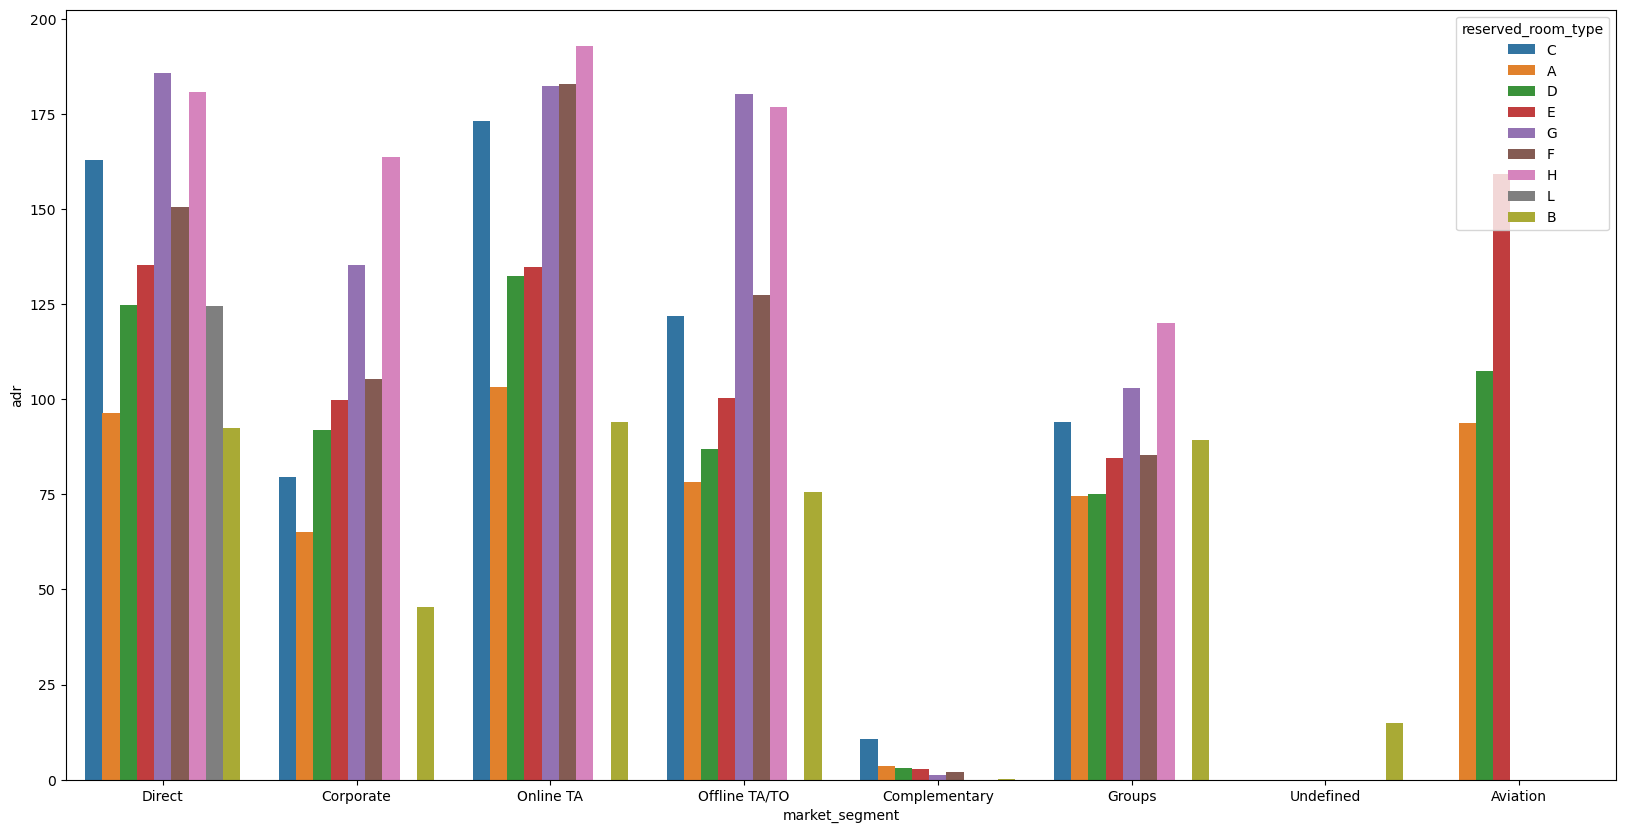

In [69]:
plt.figure(figsize=(20,10))
sns.barplot(x="market_segment" , y="adr" , hue="reserved_room_type" , data=data , errorbar=None)

### ie this plot tells avg adr of various room-types for all the market segment ..


## 7.. Total guests arrival on each day : 
         Is there any pattern in guests arrival , ie whether 
         Guests number have increased or not ? 

In [71]:
data.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015


In [72]:
data['arrival_date_month'].unique()

array(['July', 'August', 'September', 'October', 'November', 'December',
       'January', 'February', 'March', 'April', 'May', 'June'],
      dtype=object)

In [73]:
dict_month = {'July':7, 'August':8, 'September':9, 'October':10, 'November':11, 'December':12,
       'January':1, 'February':2, 'March':3, 'April':4, 'May':5, 'June':6}

In [74]:
import warnings
from warnings import filterwarnings
filterwarnings('ignore')

In [75]:
data['arrival_date_month_index'] = data['arrival_date_month'].map(dict_month)

In [76]:
data.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date',
       'arrival_date_month_index'],
      dtype='object')

In [77]:
data[['arrival_date_year',
       'arrival_date_month_index' , 'arrival_date_day_of_month']]

,arrival_date_year,arrival_date_month_index,arrival_date_day_of_month
0,2015,7,1
1,2015,7,1
2,2015,7,1
3,2015,7,1
4,2015,7,1
...,...,...,...
119385,2017,8,30
119386,2017,8,31
119387,2017,8,31
119388,2017,8,31


In [78]:
data['arrival_date'] = data['arrival_date_year'].astype(str) + '-' + data['arrival_date_month_index'].astype(str) + '-' + data['arrival_date_day_of_month'].astype(str)


'''
we need to use .astype(str) to convert int values to string , 
otherwise we are unable to perform this string concatenation operation ..
'''

'\nwe need to use .astype(str) to convert int values to string , \notherwise we are unable to perform this string concatenation operation ..\n'

In [79]:
data.head(2)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date_month_index,arrival_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015,7,2015-7-1
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015,7,2015-7-1


In [80]:
data.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date',
       'arrival_date_month_index', 'arrival_date'],
      dtype='object')

In [81]:
data[['adults', 'children', 'babies']]

,adults,children,babies
0,2,0.0,0
1,2,0.0,0
2,1,0.0,0
3,1,0.0,0
4,2,0.0,0
...,...,...,...
119385,2,0.0,0
119386,3,0.0,0
119387,2,0.0,0
119388,2,0.0,0


In [82]:
data['Total_guests'] = data['adults'] + data['children'] + data['babies']

In [83]:
data.head(2)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date_month_index,arrival_date,Total_guests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,0,Transient,0.0,0,0,Check-Out,7/1/2015,7,2015-7-1,2.0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,0,Transient,0.0,0,0,Check-Out,7/1/2015,7,2015-7-1,2.0


In [84]:
data.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date',
       'arrival_date_month_index', 'arrival_date', 'Total_guests'],
      dtype='object')

In [85]:
data[['arrival_date', 'Total_guests']]

,arrival_date,Total_guests
0,2015-7-1,2.0
1,2015-7-1,2.0
2,2015-7-1,1.0
3,2015-7-1,1.0
4,2015-7-1,2.0
...,...,...
119385,2017-8-30,2.0
119386,2017-8-31,3.0
119387,2017-8-31,2.0
119388,2017-8-31,2.0


In [86]:
dataNoCancel = data[data['is_canceled']==0]

In [87]:
guest_arrival_series = dataNoCancel.groupby(['arrival_date'])['Total_guests'].sum()

<Axes: xlabel='arrival_date'>

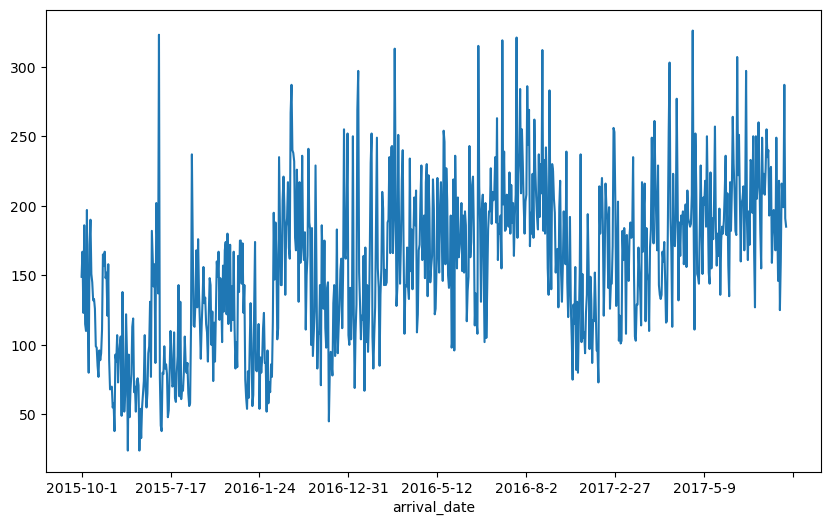

In [88]:
guest_arrival_series.plot(figsize=(10,6))

In [89]:
'''
Q.. Is there any pattern ?
Ans .. No , there is no visible pattern in guests arrival 
in this line-plot as we have some un-even trend ..

'''

'\nQ.. Is there any pattern ?\nAns .. No , there is no visible pattern in guests arrival \nin this line-plot as we have some un-even trend ..\n\n'

## 8.. Analysing distribution of "guests arrival"
     lets plot distribution of "guests arrival"

In [91]:
guest_arrival_series

arrival_date
2015-10-1     149.0
2015-10-10    167.0
2015-10-11    123.0
2015-10-12    186.0
2015-10-13    115.0
              ...  
2017-8-5      205.0
2017-8-6      199.0
2017-8-7      287.0
2017-8-8      191.0
2017-8-9      185.0
Name: Total_guests, Length: 793, dtype: float64

In [92]:
type(guest_arrival_series)

### this is a series having indexes as "arrival_dates" ..

pandas.core.series.Series

In [93]:
guest_arrival_series.values

## lets obtain array representation of Series so that it is easy to get our distribution ..

array([149., 167., 123., 186., 115., 110., 197., 118.,  80., 172., 190.,
       151., 145., 132., 133., 126.,  99.,  98.,  85.,  77.,  96.,  89.,
        94., 111., 165., 157., 167., 148., 152., 121., 158.,  89.,  68.,
        69.,  70.,  55.,  58.,  38.,  93.,  88., 107.,  73.,  92., 100.,
       106.,  49., 138.,  81.,  52.,  64., 122.,  95.,  24.,  93.,  48.,
        68.,  79., 113., 119.,  66.,  70.,  52.,  74.,  76.,  71.,  24.,
        54.,  33.,  55.,  64.,  74., 107.,  68.,  55.,  65.,  94.,  99.,
       131.,  77., 182., 161., 142., 158.,  87., 202., 174., 137., 323.,
        77.,  42.,  38.,  80.,  79.,  99.,  83.,  86.,  79.,  48.,  53.,
        80., 110.,  93.,  70.,  71., 109.,  62.,  59.,  80.,  92., 143.,
        63., 131.,  61.,  70.,  67.,  81., 106.,  87.,  80.,  87.,  65.,
        56.,  58., 111., 237., 171., 114., 113., 131., 168., 127., 176.,
       137., 116.,  90., 114., 132., 156., 130., 134., 115., 109.,  88.,
       122., 148., 143., 100., 124.,  74., 116.,  8

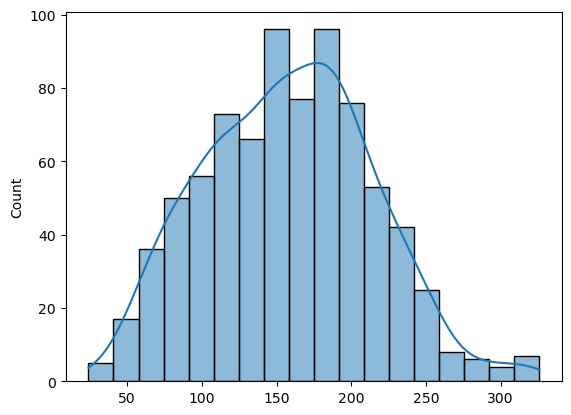

In [94]:
sns.histplot(guest_arrival_series.values, kde=True)
plt.show()


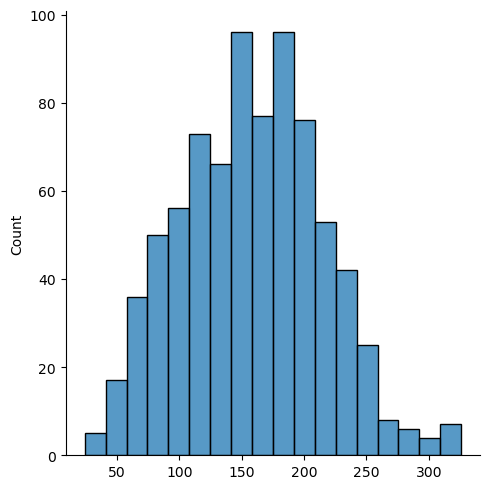

In [95]:
sns.displot(guest_arrival_series.values )

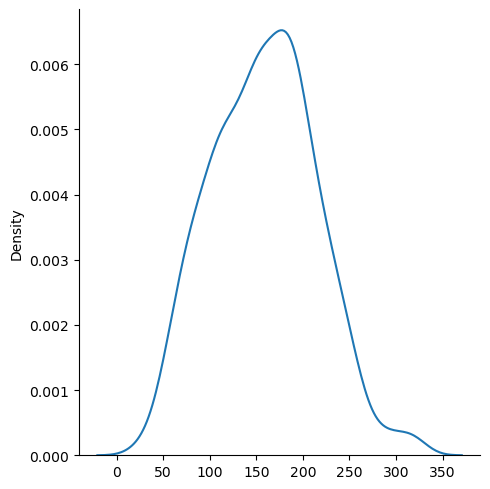

In [96]:
sns.displot(guest_arrival_series.values , kind='kde' )

In [97]:
'''


we can achieve distribution plot by smoothening our histogram using KDE  ie PDF is a smoothen form of your histogram !
ie histogram -->> apply KDE -->> we will get distribution plot 



This is called density plot bcz here height representshow many pts exists at each of these intervals 
or how dense each of the region is !



density(distribution) plot : at a point , what is a density of a data pt. ?
                or
how many percentage of data pts available at some particular pt .. ?
                or 
What is the % of data points that I will encounter at any point ? 
                or
what is the probability of certain data pt in whole data ?
                or 
prob that my data has value has some specific value 



Note : Above distribution is close to Gaussian/normal distribution , 


'''

'\n\n\nwe can achieve distribution plot by smoothening our histogram using KDE  ie PDF is a smoothen form of your histogram !\nie histogram -->> apply KDE -->> we will get distribution plot \n\n\n\nThis is called density plot bcz here height representshow many pts exists at each of these intervals \nor how dense each of the region is !\n\n\n\ndensity(distribution) plot : at a point , what is a density of a data pt. ?\n                or\nhow many percentage of data pts available at some particular pt .. ?\n                or \nWhat is the % of data points that I will encounter at any point ? \n                or\nwhat is the probability of certain data pt in whole data ?\n                or \nprob that my data has value has some specific value \n\n\n\nNote : Above distribution is close to Gaussian/normal distribution , \n\n\n'

In [98]:
# Original notebook referenced an image from a Windows computer; it is not part of this repository.


In [99]:
'''

If mean & median are equal , it means 
distribution is symmetrical & bell-shaped 

If mean > median , it means distribution is not symmetrical 
& it is Right skewed (positively skewed )

If mean < median , it means distribution is not symmetrical 
& it is Right skewed (negatively skewed )


'''

'\n\nIf mean & median are equal , it means \ndistribution is symmetrical & bell-shaped \n\nIf mean > median , it means distribution is not symmetrical \n& it is Right skewed (positively skewed )\n\nIf mean < median , it means distribution is not symmetrical \n& it is Right skewed (negatively skewed )\n\n\n'

#### Properties of Normal/Gaussian Distribution : 
     Bell shaped curve 
     Symmetrical distribution
     68-95-99 rule

In [101]:
np.mean(guest_arrival_series.values)

157.92559899117276

In [102]:
np.median(guest_arrival_series.values)

## mean & median are approx equals , 
## it means distribution is a symmetrical & bell-shaped 

158.0

In [103]:
# Original notebook referenced an image from a Windows computer; it is not part of this repository.


In [104]:
np.std(guest_arrival_series.values)

56.48263702610786

In [105]:
'''

between 1 std dev ie between u-sigma to u+sigma ie between 100 to 213 , 
we have approx 68% of data pts 
ie , approx 68% of total guests arrival values lies between interval of 100 to 213


between 2 std dev ie between u-2sigma to u+2sigma ie between 46 to 269 , 
we have approx 95% of data pts 
ie , approx 95% of total guests arrival values lies between interval of 46 to 269


between 3 std dev ie between u-3sigma to u+3sigma ie between 0 to 320 , 
we have approx 99.4% of data pts 
ie , approx 99.7% of total guests arrival values lies between interval of 0 to 320


'''

'\n\nbetween 1 std dev ie between u-sigma to u+sigma ie between 100 to 213 , \nwe have approx 68% of data pts \nie , approx 68% of total guests arrival values lies between interval of 100 to 213\n\n\nbetween 2 std dev ie between u-2sigma to u+2sigma ie between 46 to 269 , \nwe have approx 95% of data pts \nie , approx 95% of total guests arrival values lies between interval of 46 to 269\n\n\nbetween 3 std dev ie between u-3sigma to u+3sigma ie between 0 to 320 , \nwe have approx 99.4% of data pts \nie , approx 99.7% of total guests arrival values lies between interval of 0 to 320\n\n\n'